# Capítulo 5 — *The Bias–Complexity Trade-off*: simulaciones

**Curso:** Teoría de la Generalización · **Referencia:** Shalev-Shwartz & Ben-David (2014), *Understanding Machine Learning*, cap. 5.

Este notebook acompaña la exposición. Tiene una sección por tema, en el mismo orden de las diapositivas:

| § | Tema | Pregunta que responde la simulación |
|---|------|-------------------------------------|
| 1 | 5.1 No-Free-Lunch | ¿Puede un algoritmo ir bien en *todos* los etiquetados de un dominio finito? |
| 2 | 5.2 Descomposición del error | ¿Cómo cambian $\epsilon_{\text{app}}$ y $\epsilon_{\text{est}}$ al crecer la complejidad de $\mathcal{H}$? |
| 3 | Ejercicio 1 | Si $\theta\in[0,1]$ y $\mathbb{E}[\theta]\ge 1/4$, ¿qué tan pequeña puede ser $\mathbb{P}[\theta\ge 1/8]$? |
| 4 | Ejercicio 2 | ¿Cuándo conviene un rectángulo en 2D y cuándo uno en 5D, según el tamaño de muestra? |
| 5 | Ejercicio 3 | ¿Cómo se compara el error esperado con la cota $\frac{k-1}{2k}$ cuando $\lvert\mathcal{X}\rvert = km$? |

Cada sección sigue la misma estructura: **(1) pregunta**, **(2) código**, **(3) gráfica**, **(4) interpretación**.

> **Regla de lectura.** Las simulaciones *ilustran* los resultados del capítulo; **no los demuestran**. Una simulación
> solo explora unos pocos casos concretos (un algoritmo, unas distribuciones, un tamaño de muestra), mientras que los
> teoremas hablan de *todos* los algoritmos y *todas* las distribuciones. Las demostraciones están en las diapositivas.

Solo se usan `numpy` y `matplotlib`, con semilla fija para que los resultados sean reproducibles.

In [1]:
import itertools
import numpy as np
import matplotlib.pyplot as plt

SEMILLA = 2026
rng = np.random.default_rng(SEMILLA)

# Estilo sobrio y común para todas las figuras
plt.rcParams.update({
    "figure.figsize": (8, 4.5),
    "figure.dpi": 110,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "font.size": 11,
    "legend.frameon": False,
})
ACENTO = "#1d5a78"      # color principal
GRIS = "#4a4a4a"        # segunda serie (siempre con otro estilo de línea)
GRIS_CLARO = "#a8a8a8"  # referencias y cotas

---
## 1. Sección 5.1 — No-Free-Lunch

### Pregunta
El teorema dice: para **cualquier** algoritmo $A$ y $m < |\mathcal{X}|/2$ existe una distribución $\mathcal{D}$
realizable (hay $f$ con $L_\mathcal{D}(f)=0$) en la que $A$ falla. La prueba construye un dominio $C$ de $2m$ puntos,
considera los $T = 2^{2m}$ etiquetados $f_1,\dots,f_T$ y muestra que

$$\max_{i}\ \mathbb{E}_{S\sim\mathcal{D}_i^m}\big[L_{\mathcal{D}_i}(A(S))\big] \;\ge\; \frac{1}{T}\sum_{i=1}^{T}\mathbb{E}_{S\sim\mathcal{D}_i^m}\big[L_{\mathcal{D}_i}(A(S))\big] \;\ge\; \frac14 .$$

**¿Qué vamos a ver?** Tomamos $m=4$ (8 puntos, 256 etiquetados) y algoritmos concretos que *memorizan* lo que ven.
Medimos el error esperado en **cada** etiquetado $f_i$ y comprobamos que:
1. el algoritmo va bien en algunos etiquetados y mal en otros;
2. el promedio sobre etiquetados es $\ge 1/4$ **para todos los algoritmos probados** (no depende de lo "listo" que sea).

In [2]:
def todos_los_etiquetados(n_puntos):
    # Matriz (2^n, n): la fila i es la función f_i : C -> {0,1}
    return np.array(list(itertools.product([0, 1], repeat=n_puntos)))


def muestrear_indices(n_puntos, m, n_muestras, rng):
    # Cada fila es una muestra S = (x_1, ..., x_m): m puntos i.i.d. uniformes sobre C (con reemplazo)
    return rng.integers(0, n_puntos, size=(n_muestras, m))


def puntos_vistos(indices, n_puntos):
    # vistos[s, x] = True si el punto x aparece en la muestra s
    vistos = np.zeros((indices.shape[0], n_puntos), dtype=bool)
    for columna in range(indices.shape[1]):
        vistos[np.arange(indices.shape[0]), indices[:, columna]] = True
    return vistos


# --- Tres algoritmos. Todos copian la etiqueta observada en los puntos vistos;
#     solo cambian en lo que predicen sobre los puntos NO vistos. ---

def memoriza_y_predice_0(f, vistos):
    return np.where(vistos, f, 0)


def memoriza_y_predice_1(f, vistos):
    return np.where(vistos, f, 1)


def memoriza_y_vota(f, vistos):
    # En los no vistos predice la etiqueta mayoritaria entre los puntos vistos (empate -> 0)
    unos_vistos = (vistos * f).sum(axis=1)
    n_vistos = vistos.sum(axis=1)
    mayoria = (2 * unos_vistos > n_vistos).astype(int)
    return np.where(vistos, f, mayoria[:, None])


def error_verdadero(predicciones, f):
    # D_i es uniforme sobre C y etiqueta con f_i  =>  L_{D_i}(h) = fracción de puntos de C donde h(x) != f_i(x)
    return (predicciones != f).mean(axis=1)

In [3]:
m = 4
n_puntos = 2 * m            # |C| = 2m
n_muestras = 4000           # muestras S por etiquetado (Monte Carlo para la esperanza sobre S)

etiquetados = todos_los_etiquetados(n_puntos)             # T = 2^(2m) = 256 funciones
indices = muestrear_indices(n_puntos, m, n_muestras, rng)
vistos = puntos_vistos(indices, n_puntos)
# Usamos LAS MISMAS posiciones x_1..x_m para todos los f_i: es exactamente la estructura S_j^i de la prueba
# (misma secuencia de puntos, etiquetada por f_i).

algoritmos = {
    "memoriza + predice 0": memoriza_y_predice_0,
    "memoriza + predice 1": memoriza_y_predice_1,
    "memoriza + voto mayoritario": memoriza_y_vota,
}

# errores[nombre][i, s] = L_{D_i}(A(S_s))
errores = {}
for nombre, algoritmo in algoritmos.items():
    errores[nombre] = np.array([error_verdadero(algoritmo(f, vistos), f) for f in etiquetados])

print(f"T = {len(etiquetados)} etiquetados, {n_muestras} muestras por etiquetado\n")
print(f"{'algoritmo':30s} {'promedio_i E[L]':>16s} {'max_i E[L]':>12s} {'min_i E[L]':>12s}")
for nombre, E in errores.items():
    esperado_por_etiquetado = E.mean(axis=1)     # E_S[L_{D_i}(A(S))] para cada i
    print(f"{nombre:30s} {esperado_por_etiquetado.mean():16.3f} "
          f"{esperado_por_etiquetado.max():12.3f} {esperado_por_etiquetado.min():12.3f}")

# Valor exacto del promedio: cada punto no visto se equivoca en la mitad de los etiquetados
promedio_exacto = 0.5 * (1 - 1 / n_puntos) ** m
print(f"\nPromedio exacto sobre etiquetados = (1/2)(1 - 1/2m)^m = {promedio_exacto:.3f}  (>= 1/4)")

T = 256 etiquetados, 4000 muestras por etiquetado

algoritmo                       promedio_i E[L]   max_i E[L]   min_i E[L]
memoriza + predice 0                      0.293        0.586        0.000
memoriza + predice 1                      0.293        0.586        0.000
memoriza + voto mayoritario               0.293        0.366        0.000

Promedio exacto sobre etiquetados = (1/2)(1 - 1/2m)^m = 0.293  (>= 1/4)


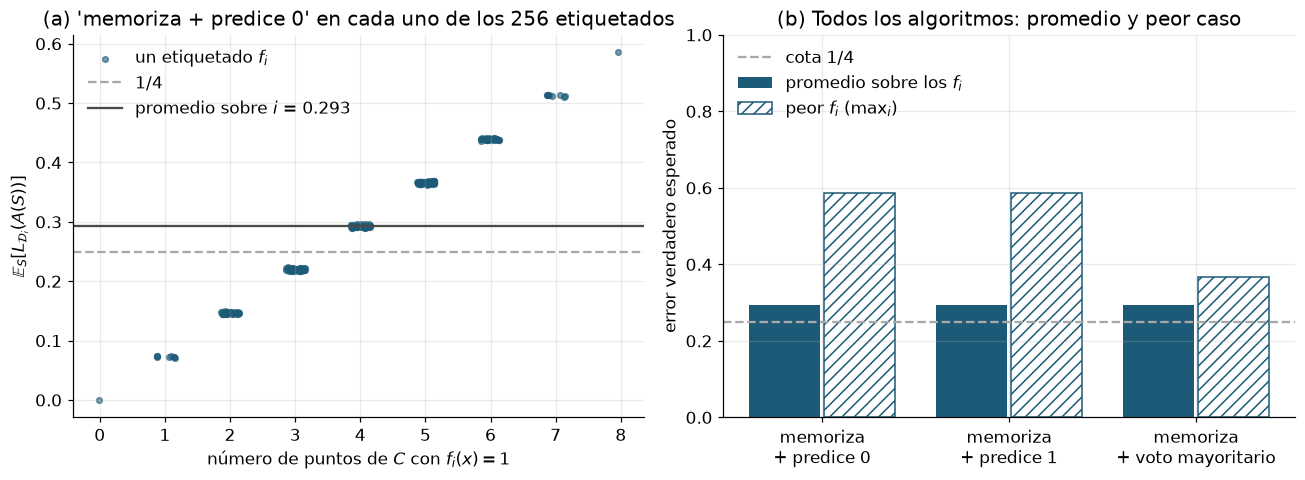

In [4]:
E0 = errores["memoriza + predice 0"].mean(axis=1)   # error esperado de cada f_i
unos_en_f = etiquetados.sum(axis=1)                   # cuántos puntos etiqueta f_i con 1

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5))

# (a) Un mismo algoritmo: bien en unos etiquetados, mal en otros
jitter = rng.uniform(-0.15, 0.15, size=len(unos_en_f))
ax1.scatter(unos_en_f + jitter, E0, s=14, color=ACENTO, alpha=0.6, label=r"un etiquetado $f_i$")
ax1.axhline(0.25, color=GRIS_CLARO, ls="--", label="1/4")
ax1.axhline(E0.mean(), color=GRIS, lw=1.5, label=f"promedio sobre $i$ = {E0.mean():.3f}")
ax1.set_xlabel(r"número de puntos de $C$ con $f_i(x)=1$")
ax1.set_ylabel(r"$\mathbb{E}_S[L_{\mathcal{D}_i}(A(S))]$")
ax1.set_title("(a) 'memoriza + predice 0' en cada uno de los 256 etiquetados")
ax1.legend(loc="upper left")

# (b) Ningún algoritmo escapa: promedio y peor caso
nombres = list(errores.keys())
promedios = [errores[n].mean() for n in nombres]
peores = [errores[n].mean(axis=1).max() for n in nombres]
pos = np.arange(len(nombres))
ax2.bar(pos - 0.2, promedios, width=0.38, color=ACENTO, label=r"promedio sobre los $f_i$")
ax2.bar(pos + 0.2, peores, width=0.38, color="white", edgecolor=ACENTO, hatch="///",
        label=r"peor $f_i$ (max$_i$)")
ax2.axhline(0.25, color=GRIS_CLARO, ls="--", label="cota 1/4")
ax2.set_xticks(pos, [n.replace(" + ", "\n+ ") for n in nombres])
ax2.set_ylabel("error verdadero esperado")
ax2.set_ylim(0, 1)
ax2.set_title("(b) Todos los algoritmos: promedio y peor caso")
ax2.legend(loc="upper left")
plt.tight_layout()
plt.show()

In [5]:
# Conexión con la versión probabilística del teorema: en el peor etiquetado, ¿cuán frecuente es L >= 1/8?
peor = np.argmax(E0)
theta_peor = errores["memoriza + predice 0"][peor]      # theta = L_D(A(S)) para cada muestra S
print(f"Peor etiquetado para 'memoriza + predice 0': f = {etiquetados[peor]}")
print(f"  E_S[L_D(A(S))]        = {theta_peor.mean():.3f}   (>= 1/4)")
print(f"  P_S[L_D(A(S)) >= 1/8] = {np.mean(theta_peor >= 1/8):.3f}   (>= 1/7 = {1/7:.3f})")

Peor etiquetado para 'memoriza + predice 0': f = [1 1 1 1 1 1 1 1]
  E_S[L_D(A(S))]        = 0.586   (>= 1/4)
  P_S[L_D(A(S)) >= 1/8] = 1.000   (>= 1/7 = 0.143)


### Interpretación (a la luz del teorema)

* **Panel (a).** El mismo algoritmo tiene error esperado $0$ cuando $f_i \equiv 0$ (su "apuesta" coincide con la
  realidad) y error cercano a $0.6$ cuando $f_i \equiv 1$. Un algoritmo **no es bueno o malo en abstracto**: es bueno
  para ciertos etiquetados y malo para otros.
* **Panel (b).** El promedio sobre los 256 etiquetados es **el mismo** ($\approx 0.29 \ge 1/4$) para los tres
  algoritmos. Esto es exactamente el "truco de parejas": en un punto no visto $v$, los etiquetados vienen en pares
  $(f_i, f_{i'})$ que solo difieren en $v$; ambos producen la misma muestra y por tanto la misma predicción, así que
  **exactamente uno** de los dos se equivoca en $v$. Por eso da igual qué regla se use en los no vistos.
* ¿Por qué $\approx 0.29$ y no exactamente $0.25$? Con muestreo con reemplazo, el número esperado de puntos no vistos
  es $2m(1-\tfrac{1}{2m})^m > m$. La prueba solo usa $p \ge m$, de ahí la cota $1/4$.
* Como el **máximo** es al menos el promedio, para cada algoritmo existe un etiquetado con error esperado $\ge 1/4$
  (aquí incluso mucho mayor). Para *ese* $\mathcal{D}$ el problema es realizable ($L_\mathcal{D}(f_i)=0$), pero el
  algoritmo no lo aprende con $m$ muestras: **no hay aprendiz universal**.
* Lo que la simulación **no** muestra: que esto valga para *todo* algoritmo y *todo* $m$. Probamos 3 algoritmos y
  $m=4$; la generalidad la da la demostración.

**Moraleja:** para aprender con pocas muestras hay que restringir de antemano los etiquetados posibles
(elegir una clase $\mathcal{H}$): eso es el **sesgo inductivo**.

---
## 2. Sección 5.2 — Descomposición del error

### Pregunta
Para $h_S \in \mathrm{ERM}_\mathcal{H}(S)$:

$$L_\mathcal{D}(h_S) = \underbrace{\min_{h\in\mathcal{H}} L_\mathcal{D}(h)}_{\epsilon_{\text{app}}} \;+\; \underbrace{\Big(L_\mathcal{D}(h_S) - \min_{h\in\mathcal{H}} L_\mathcal{D}(h)\Big)}_{\epsilon_{\text{est}}} .$$

**¿Cómo cambian $\epsilon_{\text{app}}$, $\epsilon_{\text{est}}$ y el error de entrenamiento al hacer $\mathcal{H}$ más compleja?**

**Montaje (controlado, 1D).** $x \sim U[0,1]$, etiqueta $y = f(x)$ con una $f$ de fronteras irregulares, y con
probabilidad $\eta = 0.15$ la etiqueta se voltea (ruido). La familia de clases es

$$\mathcal{H}_K = \{\,h:[0,1]\to\{0,1\}\ \text{constante en cada una de } K \text{ celdas iguales}\,\},\qquad |\mathcal{H}_K| = 2^K .$$

$K$ mide la complejidad. El ERM sobre $\mathcal{H}_K$ es simple y exacto: **voto mayoritario en cada celda**.
Como conocemos $\mathcal{D}$, podemos calcular $L_\mathcal{D}(h)$ y $\epsilon_{\text{app}}(\mathcal{H}_K)$ exactamente (en una grilla fina).

In [6]:
ETA = 0.15                                   # probabilidad de voltear la etiqueta (ruido)
X_GRILLA = (np.arange(20000) + 0.5) / 20000  # grilla fina de [0,1] para calcular L_D "exacto"


def funcion_objetivo(x):
    # f(x): 1 en regiones de [0,1] con fronteras que no coinciden con las celdas
    return (np.sin(2 * np.pi * (2.3 * x + 0.1)) > 0).astype(int)


def generar_datos(m, rng):
    x = rng.uniform(0, 1, size=m)
    y = funcion_objetivo(x)
    voltear = rng.uniform(size=m) < ETA
    y[voltear] = 1 - y[voltear]
    return x, y


def celda_de(x, K):
    # índice (0..K-1) de la celda de cada x al partir [0,1] en K celdas iguales
    return np.minimum((x * K).astype(int), K - 1)


def erm_por_celdas(x, y, K):
    # ERM sobre H_K: en cada celda, la etiqueta mayoritaria de la muestra (celda vacía o empate -> 0)
    celdas = celda_de(x, K)
    unos = np.bincount(celdas, weights=y, minlength=K)
    total = np.bincount(celdas, minlength=K)
    return (2 * unos > total).astype(int)


def predecir(etiqueta_por_celda, x):
    return etiqueta_por_celda[celda_de(x, len(etiqueta_por_celda))]


def error_verdadero_celdas(etiqueta_por_celda):
    # L_D(h) = P[h(x) != y]: vale ETA donde h coincide con f y 1 - ETA donde no
    acierta = predecir(etiqueta_por_celda, X_GRILLA) == funcion_objetivo(X_GRILLA)
    return np.mean(np.where(acierta, ETA, 1 - ETA))


def error_entrenamiento(etiqueta_por_celda, x, y):
    return np.mean(predecir(etiqueta_por_celda, x) != y)


def error_aproximacion(K):
    # El mejor h de H_K (conociendo D): en cada celda, la etiqueta que f pone en la mayor parte de la celda
    f = funcion_objetivo(X_GRILLA)
    celdas = celda_de(X_GRILLA, K)
    fraccion_unos = np.bincount(celdas, weights=f, minlength=K) / np.bincount(celdas, minlength=K)
    mejor_h = (fraccion_unos > 0.5).astype(int)
    return error_verdadero_celdas(mejor_h)

In [7]:
def curvas_de_complejidad(m, lista_K, repeticiones, rng):
    # Para cada K: promedio (sobre muestras S) de L_S(h_S) y L_D(h_S), y el error de aproximación
    entrenamiento, verdadero = [], []
    for K in lista_K:
        L_S, L_D = [], []
        for _ in range(repeticiones):
            x, y = generar_datos(m, rng)
            h_S = erm_por_celdas(x, y, K)
            L_S.append(error_entrenamiento(h_S, x, y))
            L_D.append(error_verdadero_celdas(h_S))
        entrenamiento.append(np.mean(L_S))
        verdadero.append(np.mean(L_D))
    aproximacion = [error_aproximacion(K) for K in lista_K]
    return np.array(entrenamiento), np.array(verdadero), np.array(aproximacion)


# Potencias de 2: así las clases están anidadas, H_1 ⊆ H_2 ⊆ H_4 ⊆ ... (cada celda se parte en dos)
lista_K = [1, 2, 4, 8, 16, 32, 64, 128, 256]
m_52 = 100
tr, te, app = curvas_de_complejidad(m_52, lista_K, repeticiones=300, rng=rng)
est = te - app                    # error de estimación = L_D(h_S) - min_h L_D(h)

K_opt = lista_K[int(np.argmin(te))]
print(f"m = {m_52}.  Error de Bayes = eta = {ETA}")
print(f"{'K':>4s} {'L_S(h_S)':>9s} {'L_D(h_S)':>9s} {'eps_app':>8s} {'eps_est':>8s}")
for K, a, b, c, d in zip(lista_K, tr, te, app, est):
    print(f"{K:4d} {a:9.3f} {b:9.3f} {c:8.3f} {d:8.3f}")
print(f"\nMejor complejidad para m = {m_52}: K = {K_opt}")

m = 100.  Error de Bayes = eta = 0.15
   K  L_S(h_S)  L_D(h_S)  eps_app  eps_est
   1     0.444     0.476    0.454    0.022
   2     0.430     0.479    0.454    0.025
   4     0.380     0.433    0.409    0.024
   8     0.228     0.257    0.241    0.016
  16     0.183     0.229    0.192    0.038
  32     0.150     0.262    0.190    0.072
  64     0.107     0.307    0.154    0.154
 128     0.071     0.390    0.154    0.236
 256     0.040     0.453    0.154    0.299

Mejor complejidad para m = 100: K = 16


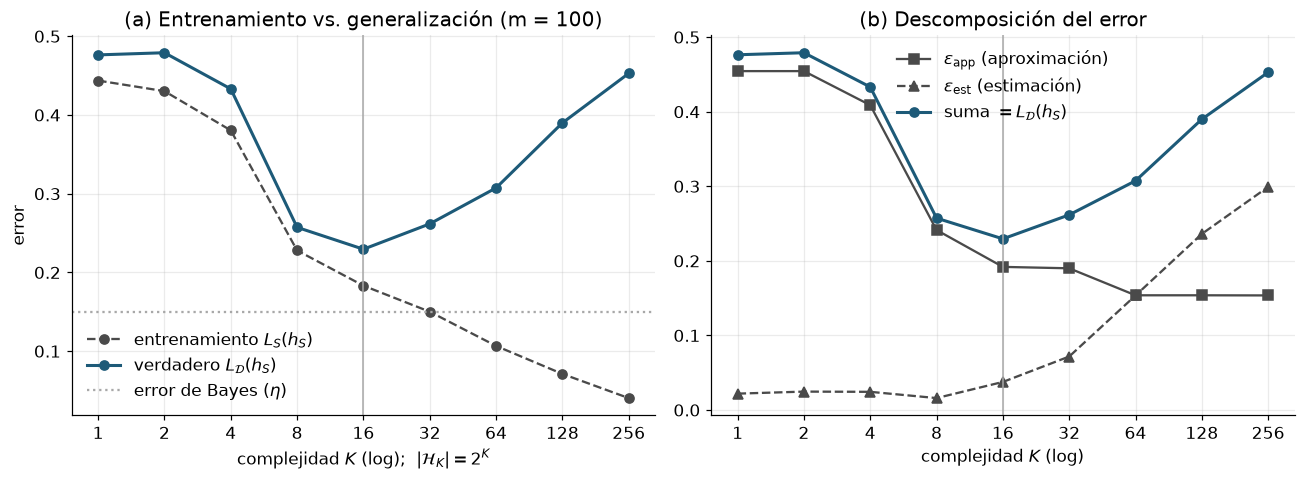

In [8]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5))

# (a) Entrenamiento vs. generalización
ax1.plot(lista_K, tr, "o--", color=GRIS, label=r"entrenamiento $L_S(h_S)$")
ax1.plot(lista_K, te, "o-", color=ACENTO, lw=2, label=r"verdadero $L_\mathcal{D}(h_S)$")
ax1.axhline(ETA, color=GRIS_CLARO, ls=":", label=r"error de Bayes ($\eta$)")
ax1.axvline(K_opt, color=GRIS_CLARO, lw=1)
ax1.set_xscale("log")
ax1.set_xticks(lista_K, [str(K) for K in lista_K])
ax1.minorticks_off()
ax1.set_xlabel(r"complejidad $K$ (log);  $|\mathcal{H}_K| = 2^K$")
ax1.set_ylabel("error")
ax1.set_title(f"(a) Entrenamiento vs. generalización (m = {m_52})")
ax1.legend()

# (b) Descomposición: aproximación + estimación
ax2.plot(lista_K, app, "s-", color=GRIS, label=r"$\epsilon_{\mathrm{app}}$ (aproximación)")
ax2.plot(lista_K, est, "^", color=GRIS, ls="--", label=r"$\epsilon_{\mathrm{est}}$ (estimación)")
ax2.plot(lista_K, te, "o-", color=ACENTO, lw=2, label=r"suma $= L_\mathcal{D}(h_S)$")
ax2.axvline(K_opt, color=GRIS_CLARO, lw=1)
ax2.set_xscale("log")
ax2.set_xticks(lista_K, [str(K) for K in lista_K])
ax2.minorticks_off()
ax2.set_xlabel(r"complejidad $K$ (log)")
ax2.set_title("(b) Descomposición del error")
ax2.legend(loc="upper center")
plt.tight_layout()
plt.show()

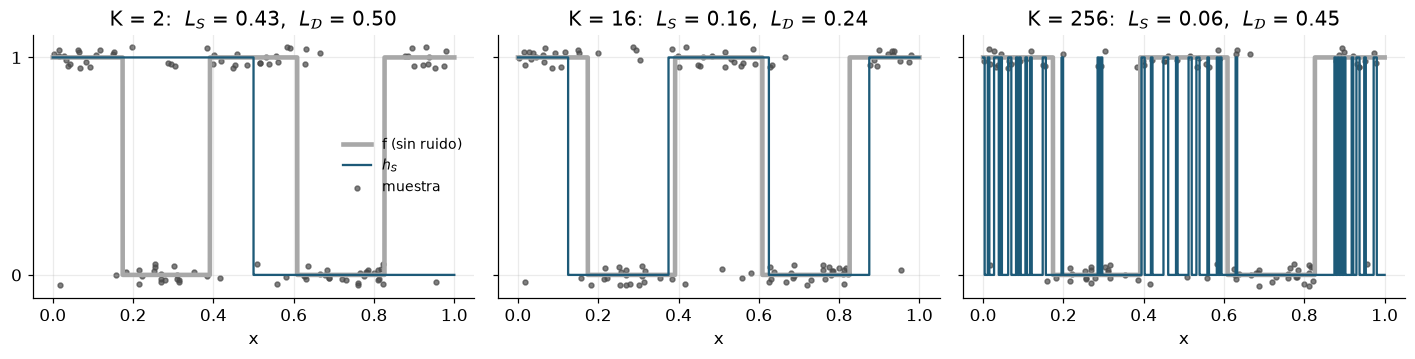

In [9]:
# Ejemplos concretos: la misma muestra ajustada con poca, media y mucha complejidad
x, y = generar_datos(m_52, rng)
fig, ejes = plt.subplots(1, 3, figsize=(13, 3.4), sharey=True)
for ax, K in zip(ejes, [2, K_opt, 256]):
    h_S = erm_por_celdas(x, y, K)
    ax.plot(X_GRILLA, funcion_objetivo(X_GRILLA), color=GRIS_CLARO, lw=3, label="f (sin ruido)")
    ax.step(X_GRILLA, predecir(h_S, X_GRILLA), color=ACENTO, lw=1.5, where="mid", label=r"$h_S$")
    ax.scatter(x, y + rng.uniform(-0.05, 0.05, size=len(y)), s=10, color=GRIS, alpha=0.7, label="muestra")
    ax.set_title(rf"K = {K}:  $L_S$ = {error_entrenamiento(h_S, x, y):.2f},  $L_\mathcal{{D}}$ = {error_verdadero_celdas(h_S):.2f}")
    ax.set_yticks([0, 1])
    ax.set_xlabel("x")
ejes[0].legend(loc="center right", fontsize=9)
plt.tight_layout()
plt.show()

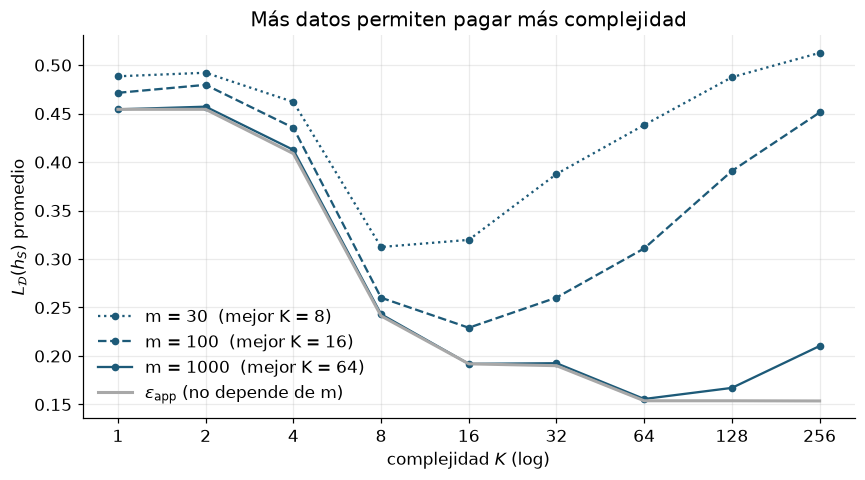

In [10]:
# ¿Cómo depende la mejor complejidad del tamaño de muestra?
fig, ax = plt.subplots(figsize=(8, 4.5))
estilos = {30: ":", 100: "--", 1000: "-"}
for m_i, estilo in estilos.items():
    _, te_i, _ = curvas_de_complejidad(m_i, lista_K, repeticiones=150, rng=rng)
    K_i = lista_K[int(np.argmin(te_i))]
    ax.plot(lista_K, te_i, estilo, marker="o", ms=4, color=ACENTO, label=f"m = {m_i}  (mejor K = {K_i})")
ax.plot(lista_K, app, color=GRIS_CLARO, lw=2, label=r"$\epsilon_{\mathrm{app}}$ (no depende de m)")
ax.set_xscale("log")
ax.set_xticks(lista_K, [str(K) for K in lista_K])
ax.minorticks_off()
ax.set_xlabel(r"complejidad $K$ (log)")
ax.set_ylabel(r"$L_\mathcal{D}(h_S)$ promedio")
ax.set_title("Más datos permiten pagar más complejidad")
ax.legend()
plt.tight_layout()
plt.show()

### Interpretación

* **Error de aproximación** (panel b, cuadrados): baja al aumentar $K$ y **no depende de $m$**. Es el precio del sesgo
  inductivo: si $\mathcal{H}_K$ no contiene nada parecido a $f$, ni con infinitos datos lo arreglamos. Nunca baja del
  error de Bayes $\eta = 0.15$ (el ruido no lo explica ninguna hipótesis).
  Como usamos $K$ potencias de 2, las clases están anidadas ($\mathcal{H}_K \subseteq \mathcal{H}_{2K}$) y el mínimo
  sobre una clase más grande no puede ser mayor: la curva es no creciente.
* **Error de estimación** (triángulos): **sube** con $K$. Con $m$ fijo, cada celda recibe en promedio $m/K$ puntos;
  con celdas casi vacías el voto mayoritario se decide por el ruido. Esto concuerda con la cota para clases finitas
  $\epsilon_{\text{est}} \lesssim \sqrt{2\log(2|\mathcal{H}|/\delta)/m}$ con $\log|\mathcal{H}_K| = K\log 2$.
* **Entrenamiento vs. verdadero** (panel a): $L_S(h_S)$ baja siempre (con $K$ grande casi memoriza la muestra), pero
  $L_\mathcal{D}(h_S)$ tiene forma de U. A la izquierda del mínimo: **underfitting** (domina $\epsilon_{\text{app}}$);
  a la derecha: **overfitting** (domina $\epsilon_{\text{est}}$). Esto es el *bias–complexity trade-off*.
* **Última figura:** al crecer $m$ la curva de estimación baja y el mínimo se desplaza hacia $K$ mayores: con más datos
  "podemos pagar" una clase más rica.

**Limitaciones.** Es una sola familia de clases, en 1D y con un $f$ elegido por nosotros; los números concretos
(p. ej. el $K$ óptimo) no son generales. Lo general es la *forma* del compromiso, que se sigue de la descomposición
y de las cotas de convergencia uniforme del capítulo 4.

---
## 3. Ejercicio 1 — De $\mathbb{E}[\theta]\ge 1/4$ a $\mathbb{P}[\theta \ge 1/8] \ge 1/7$

### Pregunta
En la prueba del NFL, $\theta = L_\mathcal{D}(A(S))$ es una variable aleatoria (aleatoria por $S$) con valores en $[0,1]$
y la Ecuación (5.2) da $\mathbb{E}[\theta] \ge 1/4$. El Lema B.1 (Markov "inverso") garantiza

$$\mathbb{P}[\theta > a] \;\ge\; \frac{\mathbb{E}[\theta]-a}{1-a}\qquad\Longrightarrow\qquad \mathbb{P}[\theta \ge 1/8] \;\ge\; \frac{\mathbb{E}[\theta]-1/8}{7/8} = \frac{8\,\mathbb{E}[\theta]-1}{7} \;\ge\; \frac17 .$$

**¿Se cumple la cota en distribuciones concretas? ¿Qué tan cerca de $1/7$ se puede llegar?**
Simulamos varias variables en $[0,1]$ con esperanza $\ge 1/4$, incluida una construida para quedar lo más cerca posible
de la cota, y luego muchas distribuciones al azar para ver la relación esperanza $\leftrightarrow$ probabilidad.

In [11]:
def prob_al_menos(muestras, umbral=1/8):
    # Estimación empírica de P[theta >= umbral]
    return np.mean(muestras >= umbral)


def cota_lema_B1(mu, a=1/8):
    # Lema B.1: P[theta > a] >= (mu - a) / (1 - a); una probabilidad nunca es negativa
    return np.maximum(0, (mu - a) / (1 - a))


def dos_puntos(a, mu, n, rng):
    # theta = 1 con probabilidad q, theta = a con probabilidad 1 - q, elegida para que E[theta] = mu
    q = (mu - a) / (1 - a)
    return np.where(rng.uniform(size=n) < q, 1.0, a)


n = 200_000
peor_nfl = errores["memoriza + predice 0"][np.argmax(E0)]   # theta real de la sección 1 (peor etiquetado)
variables = {
    "Uniforme[0,1]": rng.uniform(0, 1, n),
    "Beta(1,3)": rng.beta(1, 3, n),
    "Beta(0.5,1.5)": rng.beta(0.5, 1.5, n),
    "NFL (sección 1)": peor_nfl,
    "dos puntos {0.124, 1}": dos_puntos(0.124, 0.25, n, rng),
}

print(f"{'variable':24s} {'E[theta]':>9s} {'P[theta>=1/8]':>14s} {'cota (8E-1)/7':>14s}")
for nombre, theta in variables.items():
    mu = theta.mean()
    print(f"{nombre:24s} {mu:9.3f} {prob_al_menos(theta):14.3f} {cota_lema_B1(mu):14.3f}")
print(f"\n1/7 = {1/7:.4f}")

variable                  E[theta]  P[theta>=1/8]  cota (8E-1)/7
Uniforme[0,1]                0.499          0.874          0.428
Beta(1,3)                    0.249          0.669          0.142
Beta(0.5,1.5)                0.250          0.559          0.143
NFL (sección 1)              0.586          1.000          0.527
dos puntos {0.124, 1}        0.250          0.143          0.142

1/7 = 0.1429


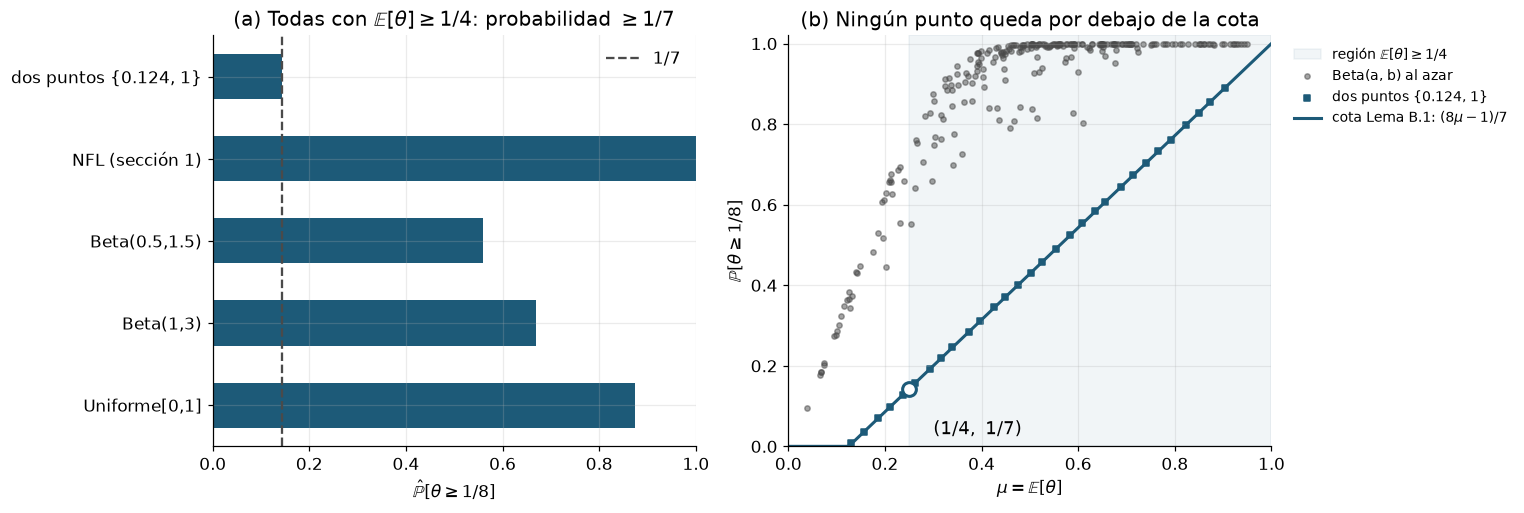

In [12]:
# Muchas distribuciones al azar en [0,1]: Betas con parámetros aleatorios y variables de dos puntos
puntos_beta, puntos_dos = [], []
for _ in range(250):
    a_, b_ = rng.uniform(0.2, 6, size=2)
    theta = rng.beta(a_, b_, 20_000)
    puntos_beta.append((theta.mean(), prob_al_menos(theta)))
for mu in np.linspace(0.13, 0.9, 30):
    theta = dos_puntos(0.124, mu, 20_000, rng)       # la familia "extremal" (casi toda la masa justo bajo 1/8)
    puntos_dos.append((theta.mean(), prob_al_menos(theta)))
puntos_beta, puntos_dos = np.array(puntos_beta), np.array(puntos_dos)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.8))

# (a) Las variables de la tabla vs. la cota 1/7
nombres = list(variables.keys())
probs = [prob_al_menos(variables[k]) for k in nombres]
ax1.barh(nombres, probs, color=ACENTO, height=0.55)
ax1.axvline(1 / 7, color=GRIS, ls="--", label="1/7")
ax1.set_xlabel(r"$\hat{\mathbb{P}}[\theta \geq 1/8]$")
ax1.set_xlim(0, 1)
ax1.set_title(r"(a) Todas con $\mathbb{E}[\theta]\geq 1/4$: probabilidad $\geq 1/7$")
ax1.legend()

# (b) Relación esperanza <-> probabilidad
mus = np.linspace(0, 1, 200)
ax2.axvspan(0.25, 1, color=ACENTO, alpha=0.06, label=r"región $\mathbb{E}[\theta] \geq 1/4$")
ax2.scatter(puntos_beta[:, 0], puntos_beta[:, 1], s=12, color=GRIS, alpha=0.5, label="Beta(a, b) al azar")
ax2.scatter(puntos_dos[:, 0], puntos_dos[:, 1], s=16, color=ACENTO, marker="s", label="dos puntos {0.124, 1}")
ax2.plot(mus, cota_lema_B1(mus), color=ACENTO, lw=2, label=r"cota Lema B.1: $(8\mu-1)/7$")
ax2.plot([0.25], [1 / 7], "o", ms=9, mfc="white", mec=ACENTO, mew=2)
ax2.annotate(r"$(1/4,\ 1/7)$", (0.25, 1 / 7), xytext=(0.30, 0.03), fontsize=12)
ax2.set_xlabel(r"$\mu = \mathbb{E}[\theta]$")
ax2.set_ylabel(r"$\mathbb{P}[\theta \geq 1/8]$")
ax2.set_title("(b) Ningún punto queda por debajo de la cota")
ax2.set_xlim(0, 1); ax2.set_ylim(0, 1.02)
ax2.legend(loc="upper left", bbox_to_anchor=(1.02, 1), fontsize=9)
plt.tight_layout()
plt.show()

### Interpretación

* **Panel (a):** todas las variables con $\mathbb{E}[\theta]\ge 1/4$ tienen $\hat{\mathbb{P}}[\theta\ge 1/8] \ge 1/7$. Las
  distribuciones "naturales" (uniforme, Beta, el $\theta$ del NFL) quedan muy por encima: la cota es de **peor caso**.
* **La variable de dos puntos** pone masa $1-q$ en $0.124$ (justo por debajo de $1/8$) y masa $q$ en $1$, con
  $\mathbb{E}[\theta]=1/4$. Así "gasta" la esperanza de la forma más eficiente posible: casi toda la masa es pequeña
  y el resto está en el máximo valor permitido, $1$. Su probabilidad es $q \approx 0.1428$, prácticamente $1/7$:
  **la cota no se puede mejorar** (se alcanza en el límite cuando el punto bajo tiende a $1/8$).
* **Panel (b):** todos los puntos $(\mathbb{E}[\theta],\ \mathbb{P}[\theta\ge 1/8])$ están sobre la recta $(8\mu-1)/7$, y la
  familia de dos puntos la recorre por encima, pegada a ella. La recta es exactamente la cota del Lema B.1 con $a=1/8$.
* **Por qué hace falta que $\theta\le 1$:** si $\theta$ no estuviera acotada, una masa diminuta en un valor enorme
  podría dar esperanza $1/4$ con probabilidad del evento tan pequeña como se quiera. La cota superior es lo que
  convierte información sobre la esperanza en información sobre la probabilidad.

**Esto no es la demostración:** 250 distribuciones al azar no cubren todas las distribuciones en $[0,1]$.
La desigualdad vale para **todas** porque se deduce del Lema B.1 (diapositivas del Ejercicio 1).

---
## 4. Ejercicio 2 — Rectángulos en 2D (BP, BMI) vs. 5D (BP, BMI, A, P, I)

### Pregunta
$\mathcal{H}_2$: rectángulos alineados con los ejes en el plano (BP, BMI). $\mathcal{H}_5$: rectángulos alineados en
$\mathbb{R}^5$. Se cumple $\mathcal{H}_2 \subseteq \mathcal{H}_5$ (un rectángulo 2D es uno 5D sin restricción en A, P, I),
así que $\epsilon_{\text{app}}(\mathcal{H}_5)\le\epsilon_{\text{app}}(\mathcal{H}_2)$, pero $\mathcal{H}_5$ es más compleja
($\mathrm{VCdim}=10$ frente a $4$). **¿Cómo cambia la elección según el número de muestras $m$?**

**Montaje (sintético, sin ningún significado clínico).** Las 5 características son uniformes en $[0,1]$ (escaladas).
La etiqueta es $1$ si el punto cae en un rectángulo verdadero 5D que depende **fuertemente** de BP y BMI y **poco** de
A, P, I (cada una recorta solo un 5 % de su rango). Algoritmo: el del libro para rectángulos, el **rectángulo más
ajustado que contiene todos los positivos** de la muestra (en 2D se usan solo las dos primeras columnas).

In [13]:
# Rectángulo verdadero en [0,1]^5. Orden de columnas: BP, BMI, A, P, I
RECT_INF = np.array([0.20, 0.20, 0.05, 0.00, 0.05])
RECT_SUP = np.array([0.80, 0.80, 1.00, 0.95, 1.00])


def dentro(X, inf, sup):
    return np.all((X >= inf) & (X <= sup), axis=1)


def generar_pacientes(m, rng):
    X = rng.uniform(0, 1, size=(m, 5))
    y = dentro(X, RECT_INF, RECT_SUP).astype(int)
    return X, y


def rectangulo_ajustado(X, y):
    # El rectángulo más pequeño (alineado con los ejes) que contiene a todos los positivos
    positivos = X[y == 1]
    if len(positivos) == 0:
        return None                       # sin positivos: se predice siempre 0
    return positivos.min(axis=0), positivos.max(axis=0)


def predecir_rect(rect, X):
    if rect is None:
        return np.zeros(len(X), dtype=int)
    inf, sup = rect
    return dentro(X, inf, sup).astype(int)


X_test, y_test = generar_pacientes(40_000, rng)   # muestra grande para estimar L_D


def error_generalizacion(m, columnas, rng):
    X, y = generar_pacientes(m, rng)
    rect = rectangulo_ajustado(X[:, columnas], y)
    return np.mean(predecir_rect(rect, X_test[:, columnas]) != y_test)


# Error de aproximación de H_2: el mejor rectángulo en (BP, BMI) es [0.2,0.8]^2 (predice 1 donde BP y BMI están en rango)
app_2d = np.mean(dentro(X_test[:, :2], RECT_INF[:2], RECT_SUP[:2]).astype(int) != y_test)
print(f"Fracción de positivos: {y_test.mean():.3f}")
print(f"eps_app(H_2) ~ {app_2d:.3f}    eps_app(H_5) = 0 (el problema es realizable en 5D)")

Fracción de positivos: 0.309
eps_app(H_2) ~ 0.052    eps_app(H_5) = 0 (el problema es realizable en 5D)


In [14]:
tamanos = [5, 10, 20, 30, 50, 75, 100, 150, 200, 300, 500, 800, 1200, 2000]
repeticiones = 200
DOS_D, CINCO_D = [0, 1], [0, 1, 2, 3, 4]

err_2d = np.array([[error_generalizacion(m, DOS_D, rng) for _ in range(repeticiones)] for m in tamanos])
err_5d = np.array([[error_generalizacion(m, CINCO_D, rng) for _ in range(repeticiones)] for m in tamanos])
media_2d, media_5d = err_2d.mean(axis=1), err_5d.mean(axis=1)

print(f"{'m':>5s} {'L_D 2D':>8s} {'L_D 5D':>8s}  mejor")
for m, a, b in zip(tamanos, media_2d, media_5d):
    print(f"{m:5d} {a:8.3f} {b:8.3f}  {'2D' if a < b else '5D'}")

    m   L_D 2D   L_D 5D  mejor
    5    0.287    0.306  2D
   10    0.250    0.292  2D
   20    0.180    0.249  2D
   30    0.147    0.210  2D
   50    0.114    0.155  2D
   75    0.095    0.107  2D
  100    0.085    0.084  5D
  150    0.073    0.061  5D
  200    0.068    0.049  5D
  300    0.062    0.032  5D
  500    0.059    0.020  5D
  800    0.056    0.013  5D
 1200    0.055    0.008  5D
 2000    0.054    0.005  5D


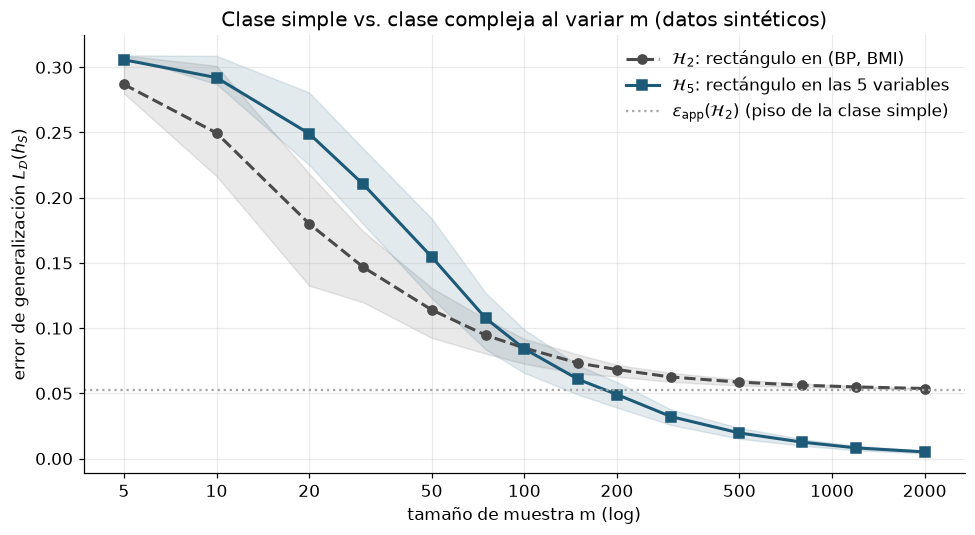

Con estos datos, 5D empieza a ganar alrededor de m = 100


In [15]:
fig, ax = plt.subplots(figsize=(9, 5))
series = [(err_2d, media_2d, "o--", GRIS, r"$\mathcal{H}_2$: rectángulo en (BP, BMI)"),
          (err_5d, media_5d, "s-", ACENTO, r"$\mathcal{H}_5$: rectángulo en las 5 variables")]
for errs, media, estilo, color, etiqueta in series:
    ax.plot(tamanos, media, estilo, color=color, lw=2, label=etiqueta)
    # banda con el 50 % central de las repeticiones (variabilidad debida a la muestra)
    ax.fill_between(tamanos, np.percentile(errs, 25, axis=1), np.percentile(errs, 75, axis=1),
                    color=color, alpha=0.12)
ax.axhline(app_2d, color=GRIS_CLARO, ls=":", label=r"$\epsilon_{\mathrm{app}}(\mathcal{H}_2)$ (piso de la clase simple)")
ax.set_xscale("log")
ax.set_xticks([5, 10, 20, 50, 100, 200, 500, 1000, 2000], ["5", "10", "20", "50", "100", "200", "500", "1000", "2000"])
ax.minorticks_off()
ax.set_xlabel("tamaño de muestra m (log)")
ax.set_ylabel(r"error de generalización $L_\mathcal{D}(h_S)$")
ax.set_title("Clase simple vs. clase compleja al variar m (datos sintéticos)")
ax.legend()
plt.tight_layout()
plt.show()

cruce = next(m for m, a, b in zip(tamanos, media_2d, media_5d) if b < a)
print(f"Con estos datos, 5D empieza a ganar alrededor de m = {cruce}")

### Interpretación

* **Pocos datos ($m$ pequeño): gana 2D.** El rectángulo 5D debe estimar 10 bordes con los mismos positivos; cada borde
  queda "encogido" hacia adentro y el clasificador rechaza muchos positivos. Es **error de estimación**: la clase es
  demasiado rica para la cantidad de datos.
* **Muchos datos: gana 5D.** Su error tiende a $0$ porque el problema es realizable en $\mathcal{H}_5$
  ($\epsilon_{\text{app}}=0$). El de 2D se estanca en el piso $\epsilon_{\text{app}}(\mathcal{H}_2)\approx 0.05$: por
  muchos datos que tenga, un rectángulo en (BP, BMI) **no puede** representar la dependencia en A, P, I. Eso es
  **error de aproximación**.
* **El cruce** es el *bias–complexity trade-off* en acción: la clase adecuada depende de $m$. Coincide con la teoría:
  la complejidad muestral de rectángulos en $\mathbb{R}^d$ crece con $d$ (cota del libro $\approx 2d\log(2d/\delta)/\epsilon$),
  así que 5D necesita del orden de 2.5 veces más datos para el mismo $\epsilon$.
* Las bandas muestran que con $m$ pequeño la variabilidad (dependencia de la muestra concreta) es mayor en 5D.

**Limitaciones.** El punto exacto del cruce depende de cuánto importan A, P, I en *nuestro* rectángulo verdadero
(si importaran mucho, 5D ganaría antes; si no importaran nada, 2D ganaría siempre). La simulación no dice nada sobre
pacientes reales: solo ilustra el compromiso estadístico.

---
## 5. Ejercicio 3 — Dominios de tamaño $|\mathcal{X}| = km$ y la cota $\frac{k-1}{2k}$

### Pregunta
Si $|C| = km$, cada muestra de $m$ puntos deja al menos $p \ge (k-1)m$ puntos sin ver, y la prueba da

$$\frac{1}{T}\sum_{i=1}^{T} \mathbb{E}_{S\sim\mathcal{D}_i^m}\big[L_{\mathcal{D}_i}(A(S))\big] \;\ge\; \frac{k-1}{2k} = \frac12 - \frac{1}{2k}.$$

**¿Cómo se compara el error esperado de un algoritmo concreto con esa cota al variar $k$? ¿Tiende a $1/2$?**
Promediamos sobre etiquetados **uniformes al azar** (equivale a promediar sobre los $2^{km}$ etiquetados) y sobre muestras $S$.
Hacemos dos versiones: muestreo i.i.d. **con reemplazo** (el del teorema) y **sin reemplazo** (el caso en que la muestra
tiene exactamente $m$ puntos distintos, que es el peor caso de la prueba: $p = (k-1)m$).

In [16]:
def error_promedio_dominio_km(k, m, repeticiones, rng, con_reemplazo=True):
    n_puntos = k * m
    errores_k = []
    for _ in range(repeticiones):
        f = rng.integers(0, 2, size=n_puntos)                      # etiquetado uniforme al azar
        indices = rng.choice(n_puntos, size=m, replace=con_reemplazo)
        vistos = np.zeros(n_puntos, dtype=bool)
        vistos[indices] = True
        h = np.where(vistos, f, 0)                                 # memoriza + predice 0
        errores_k.append(np.mean(h != f))
    return np.mean(errores_k)


m_e3 = 5
lista_k = list(range(2, 21))
emp_con = [error_promedio_dominio_km(k, m_e3, 6000, rng, con_reemplazo=True) for k in lista_k]
emp_sin = [error_promedio_dominio_km(k, m_e3, 6000, rng, con_reemplazo=False) for k in lista_k]
cota = [(k - 1) / (2 * k) for k in lista_k]

print(f"{'k':>3s} {'con reemplazo':>14s} {'sin reemplazo':>14s} {'(k-1)/(2k)':>11s}")
for k, a, b, c in zip(lista_k, emp_con, emp_sin, cota):
    print(f"{k:3d} {a:14.4f} {b:14.4f} {c:11.4f}")

  k  con reemplazo  sin reemplazo  (k-1)/(2k)
  2         0.2934         0.2490      0.2500
  3         0.3577         0.3345      0.3333
  4         0.3856         0.3713      0.3750
  5         0.4073         0.4025      0.4000
  6         0.4221         0.4154      0.4167
  7         0.4315         0.4281      0.4286
  8         0.4417         0.4366      0.4375
  9         0.4466         0.4452      0.4444
 10         0.4512         0.4514      0.4500
 11         0.4566         0.4545      0.4545
 12         0.4598         0.4580      0.4583
 13         0.4636         0.4613      0.4615
 14         0.4658         0.4643      0.4643
 15         0.4680         0.4674      0.4667
 16         0.4688         0.4690      0.4688
 17         0.4710         0.4711      0.4706
 18         0.4734         0.4724      0.4722
 19         0.4728         0.4728      0.4737
 20         0.4751         0.4741      0.4750


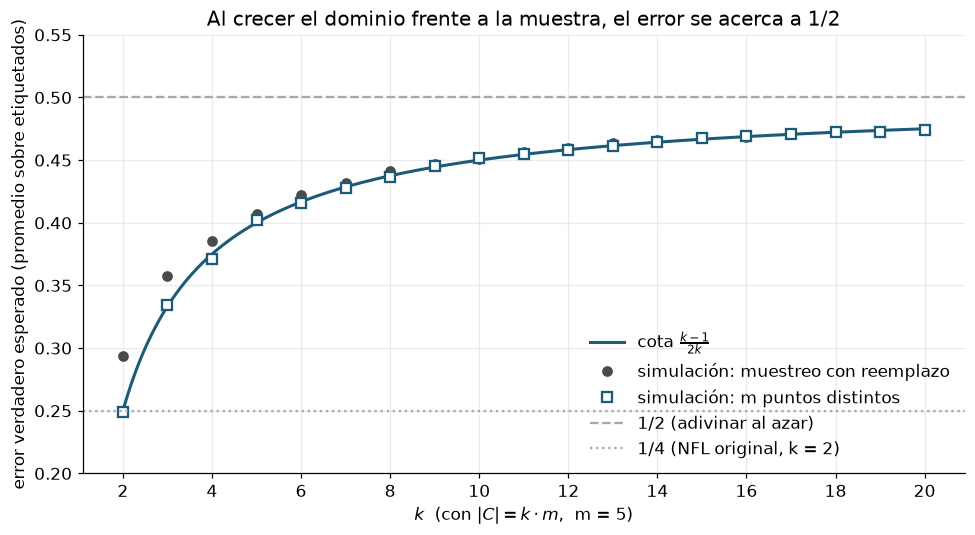

In [17]:
fig, ax = plt.subplots(figsize=(9, 5))
k_fino = np.linspace(2, 20, 300)
ax.plot(k_fino, (k_fino - 1) / (2 * k_fino), color=ACENTO, lw=2, label=r"cota $\frac{k-1}{2k}$")
ax.plot(lista_k, emp_con, "o", color=GRIS, ms=6, label="simulación: muestreo con reemplazo")
ax.plot(lista_k, emp_sin, "s", mfc="white", mec=ACENTO, ms=7, mew=1.5, label="simulación: m puntos distintos")
ax.axhline(0.5, color=GRIS_CLARO, ls="--", label="1/2 (adivinar al azar)")
ax.axhline(0.25, color=GRIS_CLARO, ls=":", label="1/4 (NFL original, k = 2)")
ax.set_xticks(lista_k[::2])
ax.set_xlabel(r"$k$  (con $|C| = k\cdot m$,  m = %d)" % m_e3)
ax.set_ylabel("error verdadero esperado (promedio sobre etiquetados)")
ax.set_title(r"Al crecer el dominio frente a la muestra, el error se acerca a 1/2")
ax.set_ylim(0.2, 0.55)
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

### Interpretación

* **Sin reemplazo** (cuadrados): la muestra ve exactamente $m$ puntos, quedan $(k-1)m$ sin ver, y cada uno se falla
  en la mitad de los etiquetados. El error promedio es $\frac{(k-1)m}{km}\cdot\frac12 = \frac{k-1}{2k}$: los puntos
  caen **sobre** la curva. Es el caso que la prueba acota, y muestra que la cota es la adecuada para el promedio.
* **Con reemplazo** (círculos): las repeticiones dejan aún más puntos sin ver, así que el error queda **por encima** de
  la cota, como debe ser.
* **Tendencia:** $\frac{k-1}{2k} = \frac12 - \frac{1}{2k} \to \frac12$. Si la muestra cubre una fracción $1/k$ cada vez
  menor del dominio, el mejor algoritmo posible (en el peor caso) no hace nada mejor que **lanzar una moneda**.
  Con $k=2$ se recupera el $1/4$ del teorema original.
* Como el teorema habla del **máximo** sobre etiquetados y aquí medimos el **promedio**, lo que vemos es un piso: para
  cada algoritmo existe un etiquetado que lo hace al menos así de mal.

**Límite de la simulación:** un solo algoritmo, un solo $m$ y $k \le 20$. La afirmación para todo $A$, todo $m < |\mathcal{X}|/k$
y todo $k\ge2$ la da la demostración del Ejercicio 3.

---
## Cierre

| Tema | Idea que debe quedar |
|------|---------------------|
| 5.1 | Sin supuestos previos, cualquier algoritmo falla en alguna tarea realizable: **se necesita sesgo inductivo**. |
| 5.2 | $L_\mathcal{D}(h_S) = \epsilon_{\text{app}} + \epsilon_{\text{est}}$: una clase rica baja el primero y sube el segundo. |
| Ej. 1 | Una variable en $[0,1]$ con $\mathbb{E}\ge 1/4$ cumple $\mathbb{P}[\,\ge 1/8\,]\ge 1/7$, y $1/7$ es alcanzable en el límite. |
| Ej. 2 | Con pocos datos conviene la clase simple (2D); con muchos, la rica (5D). |
| Ej. 3 | Si $|\mathcal{X}|\ge km$, el error esperado en el peor caso es $\ge \frac12-\frac1{2k}\to\frac12$. |